In [25]:
%pip install pygad

Note: you may need to restart the kernel to use updated packages.


Question 1 Part 1

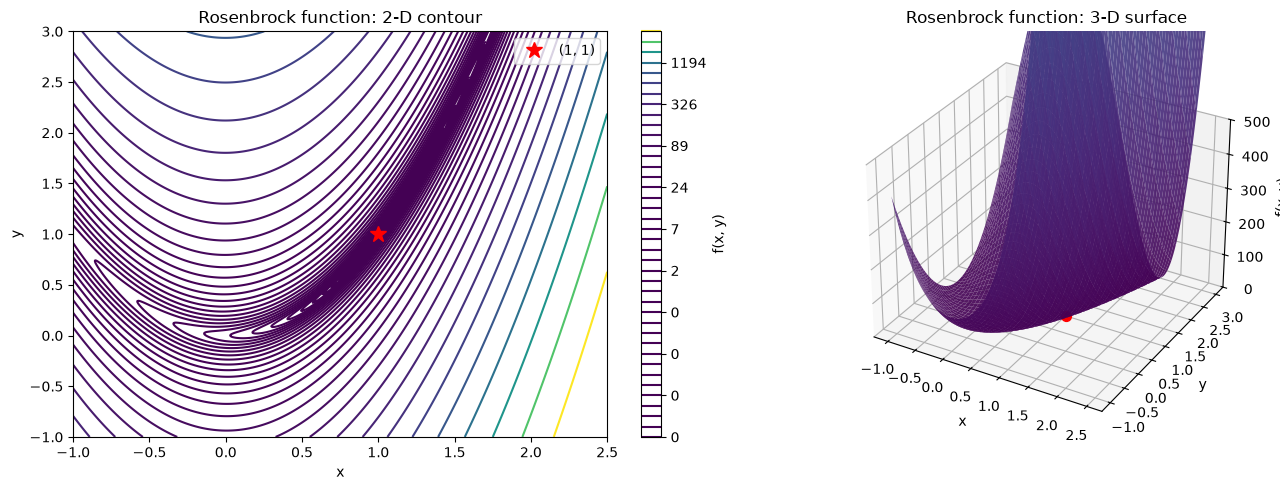

Start A: x0=[0.2 0.3] | solution=[1. 1.] | f=6.94892780267e-27 | nit=23 | nfev=30 | time=0.005641 s | success=True
Start B: x0=[1.2 1.5] | solution=[1. 1.] | f=4.57445647796e-27 | nit=14 | nfev=17 | time=0.002744 s | success=True
Start C: x0=[0.7 0.7] | solution=[1. 1.] | f=4.51746127755e-27 | nit=15 | nfev=19 | time=0.001725 s | success=True


In [26]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pygad
from scipy.optimize import minimize


# %% Problem 1 - Part 1: SciPy BFGS, with 2-D and 3-D plots
def rosenbrock(point):
    """f(x, y) = (1-x)^2 + 100(y-x^2)^2."""
    x, y = point
    return (1.0 - x) ** 2 + 100.0 * (y - x**2) ** 2


def grad_rosenbrock(point):
    """Analytical gradient used by BFGS."""
    x, y = point
    return np.array(
        [
            -2.0 * (1.0 - x) - 400.0 * x * (y - x**2),
            200.0 * (y - x**2),
        ]
    )


# Visualise the function before interpreting the optimisation result.
x = np.linspace(-1.0, 2.50, 500)
y = np.linspace(-1.0, 3.0, 500)
X, Y = np.meshgrid(x, y)
Z = rosenbrock((X, Y))

fig = plt.figure(figsize=(14, 5))
ax1 = fig.add_subplot(1, 2, 1)
contours = ax1.contour(X, Y, Z, levels=np.logspace(-2, 3.5, 40), cmap="viridis")
fig.colorbar(contours, ax=ax1, label="f(x, y)")
ax1.plot(1.0, 1.0, "r*", ms=12, label="(1, 1)")
ax1.set(title="Rosenbrock function: 2-D contour", xlabel="x", ylabel="y")
ax1.legend()

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(X, Y, Z, cmap="viridis", linewidth=0, alpha=0.9)
ax2.scatter(1.0, 1.0, 0.0, c="r", s=50)
ax2.set(title="Rosenbrock function: 3-D surface", xlabel="x", ylabel="y", zlabel="f(x, y)")
ax2.set_zlim(0, 500)  # Makes the narrow valley visible.
plt.tight_layout()
plt.show()


initial_guesses_p1 = {
    "A": np.array([0.2, 0.3]),
    "B": np.array([1.2, 1.5]),
    "C": np.array([0.7, 0.7]),
}

scipy_results_p1 = {}
for label, x0 in initial_guesses_p1.items():
    t0 = time.perf_counter()
    result = minimize(
        rosenbrock,
        x0,
        jac=grad_rosenbrock,
        method="BFGS",
        options={"gtol": 1e-10, "maxiter": 10_000},
    )
    elapsed = time.perf_counter() - t0

    scipy_results_p1[label] = {
        "initial_guess": x0,
        "solution": result.x,
        "value": float(result.fun),
        "iterations": int(result.nit),
        "function_evaluations": int(result.nfev),
        "time_s": elapsed,
        "success": bool(result.success),
    }
    print(
        f"Start {label}: x0={x0} | solution={result.x} | f={result.fun:.12g} | "
        f"nit={result.nit} | nfev={result.nfev} | time={elapsed:.6f} s | "
        f"success={result.success}"
    )

Conclusion:
Every successful run should give (1, 1), f = 0.
Because f is a sum of squares and f(1, 1)=0, this is the unique global minimum.


Question 1 Part 2

Seeded population A: centre=[0.2 0.3] | solution=[0.96491941 0.93116997] | f=0.00123165742295 | generations=1000 | objective calls=76131 | time=2.623149 s
Seeded population B: centre=[1.2 1.5] | solution=[0.98579974 0.96986571] | f=0.000576229912453 | generations=1000 | objective calls=76130 | time=2.394042 s
Seeded population C: centre=[0.7 0.7] | solution=[0.9847845  0.97070837] | f=0.000313932928578 | generations=1000 | objective calls=76129 | time=2.372621 s


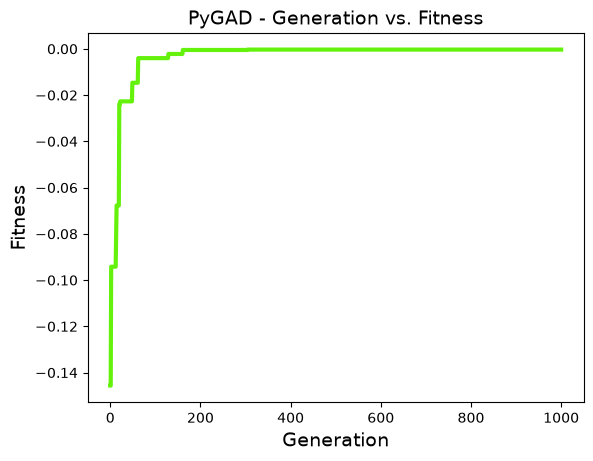

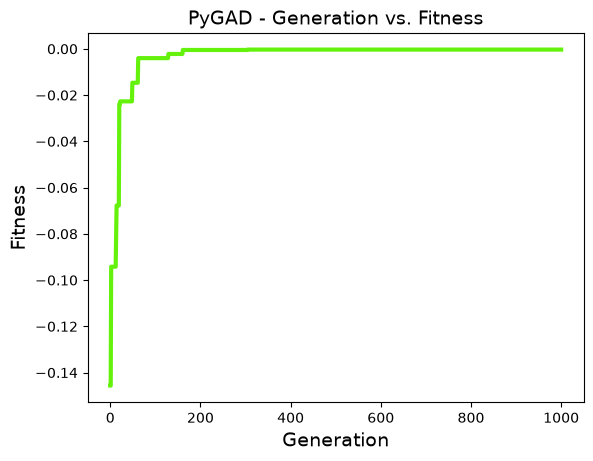

In [27]:
def rosenbrock(point):
    x, y = point
    return (1.0 - x) ** 2 + 100.0 * (y - x**2) ** 2


def seeded_population(center, lower, upper, population_size, seed):
    
    rng = np.random.default_rng(seed)
    center = np.asarray(center, dtype=float)
    lower = np.asarray(lower, dtype=float)
    upper = np.asarray(upper, dtype=float)

    population = rng.uniform(lower, upper, size=(population_size, 2))
    local_count = population_size // 2
    spread = 0.25 * (upper - lower)
    population[:local_count] = center + rng.normal(
        loc=0.0, scale=spread, size=(local_count, 2)
    )
    population = np.clip(population, lower, upper)
    population[0] = np.clip(center, lower, upper)
    return population


p1_lower = np.array([-3.0, -2.0])
p1_upper = np.array([3.0, 4.0])
p1_gene_space = [
    {"low": p1_lower[0], "high": p1_upper[0]},
    {"low": p1_lower[1], "high": p1_upper[1]},
]


def run_ga_p1(center, seed):
    objective_calls = 0

    def fitness(ga_instance, solution, solution_idx):
        # PyGAD maximises fitness, hence the negative objective.
        nonlocal objective_calls
        objective_calls += 1
        return -float(rosenbrock(solution))

    initial_population = seeded_population(
        center, p1_lower, p1_upper, population_size=80, seed=seed
    )
    ga = pygad.GA(
        num_generations=1_000,
        num_parents_mating=40,
        initial_population=initial_population,
        fitness_func=fitness,
        gene_space=p1_gene_space,
        parent_selection_type="tournament",
        K_tournament=3,
        keep_elitism=4,
        crossover_type="single_point",
        mutation_type="random",
        mutation_num_genes=1,
        random_seed=seed,
        suppress_warnings=True,
    )

    t0 = time.perf_counter()
    ga.run()
    elapsed = time.perf_counter() - t0
    solution, _, _ = ga.best_solution()

    return {
        "initial_center": np.asarray(center, dtype=float),
        "solution": np.asarray(solution, dtype=float),
        "value": float(rosenbrock(solution)),
        "iterations": int(ga.generations_completed),
        "function_evaluations": objective_calls,
        "time_s": elapsed,
        "ga": ga,
    }


ga_centers_p1 = {
    "A": np.array([0.2, 0.3]),
    "B": np.array([1.2, 1.5]),
    "C": np.array([0.7, 0.7]),
}

ga_results_p1 = {}
for run_number, (label, center) in enumerate(ga_centers_p1.items(), start=1):
    ga_results_p1[label] = run_ga_p1(center, seed=100 + run_number)
    row = ga_results_p1[label]
    print(
        f"Seeded population {label}: centre={center} | solution={row['solution']} | "
        f"f={row['value']:.12g} | generations={row['iterations']} | "
        f"objective calls={row['function_evaluations']} | time={row['time_s']:.6f} s"
    )
#Optional convergence plot for the final GA run:
ga_results_p1["C"]["ga"].plot_fitness()

Genetic algorithms is stochastic, so coordinates can vary slightly between runs, but a solution with f approximately zero is the global minimum (1, 1).


Question 1 Part 3:Compare BFGS and GA at the same decimal-place level

In [17]:
DECIMALS = 3
target_p1 = np.array([1.0, 1.0])


def matches_decimal_places(solution, target, decimals):
    """True if the coordinates agree after rounding to the requested precision."""
    tolerance = 0.5 * 10.0 ** (-decimals)
    return np.allclose(solution, target, atol=tolerance, rtol=0.0)


best_scipy_p1 = min(scipy_results_p1.values(), key=lambda row: row["value"])
best_ga_p1 = min(ga_results_p1.values(), key=lambda row: row["value"])

print(f"Comparison precision: {DECIMALS} decimal places")
print("Method       solution (x, y)                 f(x, y)       iterations   nfev       time (s)   meets precision")
print("-" * 116)
for method, row in (("SciPy BFGS", best_scipy_p1), ("PyGAD GA", best_ga_p1)):
    solution_text = np.array2string(row["solution"], precision=DECIMALS)
    meets = matches_decimal_places(row["solution"], target_p1, DECIMALS)
    print(
        f"{method:<12} {solution_text:<31} {row['value']:<12.6g} "
        f"{row['iterations']:<12} {row['function_evaluations']:<10} "
        f"{row['time_s']:<10.6f} {meets}"
    )

if not matches_decimal_places(best_ga_p1["solution"], target_p1, DECIMALS):
    print("\nThe GA did not reach the chosen precision in this run. Increase num_generations or population size and run again.")


Comparison precision: 3 decimal places
Method       solution (x, y)                 f(x, y)       iterations   nfev       time (s)   meets precision
--------------------------------------------------------------------------------------------------------------------
SciPy BFGS   [1. 1.]                         4.51746e-27  15           19         0.004236   True
PyGAD GA     [0.985 0.971]                   0.000313933  1000         76129      2.913905   False

The GA did not reach the chosen precision in this run. Increase num_generations or population size and run again.


Scipy's approach is more direct and converges quickly. GA's generations involve evaluating an entire population, making each step more computationally expensive.

Question 2 part 1&2

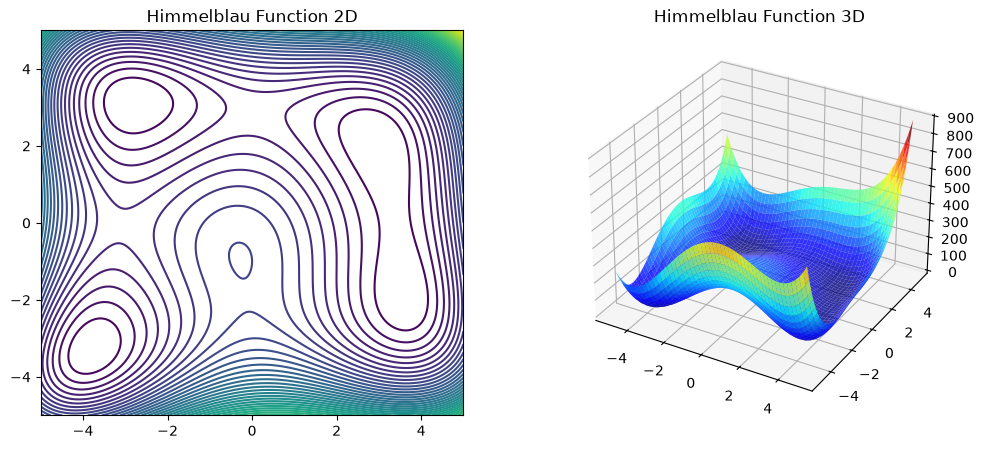

Initial guess [0, 0], Result: [2.99999994 1.99999999], Value: 1.3782273267389757e-13, Success: True, Iterations: 10
Initial guess [-4, 4], Result: [-2.80511803  3.13131251], Value: 1.0206446176713682e-13, Success: True, Iterations: 10
Initial guess [4, 0], Result: [ 3.58442834 -1.84812653], Value: 2.263853503678799e-16, Success: True, Iterations: 8
PyGAD initial guess [0, 0], Solution: [2.99228107 1.99989799], Value: 0.002214928003889362
PyGAD initial guess [-4, 4], Solution: [3.00289938 2.00971691], Value: 0.002487964438338798
PyGAD initial guess [4, 0], Solution: [2.99139829 2.00110471], Value: 0.0025608260168919557


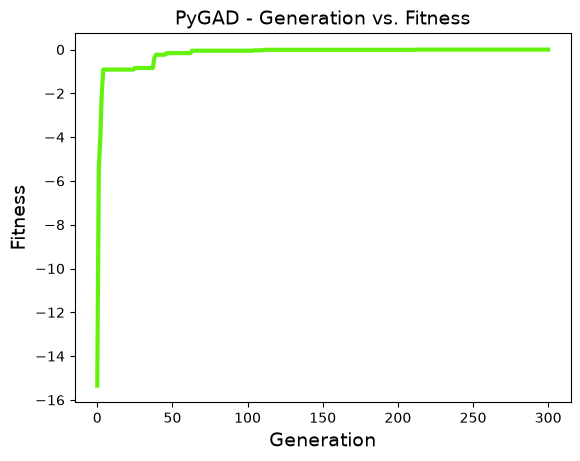

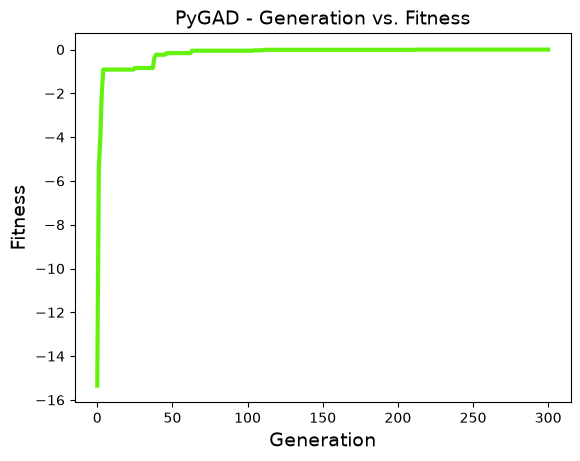

In [28]:
def himmelblau(x):
    x = np.asarray(x) # Convert to numpy array
    return (x[0]**2 + x[1] - 11)**2 + (x[0] + x[1]**2 - 7)**2

# 2D & 3D plots
x_range = np.linspace(-5, 5, 400)
y_range = np.linspace(-5, 5, 400)
X, Y = np.meshgrid(x_range, y_range)
Z = himmelblau([X, Y])

fig = plt.figure(figsize=(12,5))
ax1 = fig.add_subplot(121)
cp = ax1.contour(X, Y, Z, levels=50)
ax1.set_title("Himmelblau Function 2D")
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(X, Y, Z, cmap='jet', alpha=0.8)
ax2.set_title("Himmelblau Function 3D")
plt.show()

# Scipy Optimization
init_guesses = [[0, 0], [-4, 4], [4, 0]]
for guess in init_guesses:
    result = minimize(himmelblau, guess, method='BFGS')
    print(f"Initial guess {guess}, Result: {result.x}, Value: {result.fun}, Success: {result.success}, Iterations: {result.nit}") # TODO include time taken

# PyGAD Optimization
def fitness_func2(ga_instance, solution, solution_idx):
    return -himmelblau(solution)
for guess in init_guesses:
    ga_instance = pygad.GA(num_generations=300,
                           sol_per_pop=30,
                           num_genes=2,
                           num_parents_mating=12,
                           fitness_func=fitness_func2,
                           init_range_low=-5,
                           init_range_high=5,
                           gene_space={'low':-5, 'high':5})
    ga_instance.run()
    solution, solution_fitness, _ = ga_instance.best_solution()
    print(f"PyGAD initial guess {guess}, Solution: {solution}, Value: {himmelblau(solution)}") # TODO include iterations and time taken
ga_instance.plot_fitness()

Question 2 part 3

In [29]:
import time
import numpy as np
import pygad
from scipy.optimize import minimize

def himmelblau(x):
    x = np.asarray(x)
    return (x[0]**2 + x[1] - 11)**2 + (x[0] + x[1]**2 - 7)**2


init_guesses = [[0, 0], [-4, 4], [4, 0]]
scipy_results = []
ga_results = []

# ---------------- SciPy BFGS ----------------
for guess in init_guesses:
    start_time = time.perf_counter()
    result = minimize(himmelblau, guess, method="BFGS")
    elapsed_time = time.perf_counter() - start_time

    scipy_results.append({
        "initial_guess": guess,
        "solution": result.x,
        "value": result.fun,
        "iterations": result.nit,
        "nfev": result.nfev,
        "time": elapsed_time
    })

# ---------------- PyGAD ----------------
def create_initial_population(center, population_size=30, seed=1):
    rng = np.random.default_rng(seed)

    population = rng.uniform(-5, 5, size=(population_size, 2))
    population[:population_size // 2] = center + rng.normal(
        loc=0,
        scale=1.5,
        size=(population_size // 2, 2)
    )

    population = np.clip(population, -5, 5)
    population[0] = center
    return population


for run_number, guess in enumerate(init_guesses, start=1):
    objective_calls = 0

    def fitness_func2(ga_instance, solution, solution_idx):
        nonlocal_objective = himmelblau(solution)
        return -float(nonlocal_objective)

    initial_population = create_initial_population(
        center=np.array(guess),
        seed=100 + run_number
    )

    ga_instance = pygad.GA(
        num_generations=300,
        num_parents_mating=12,
        initial_population=initial_population,
        fitness_func=fitness_func2,
        gene_space=[
            {"low": -5, "high": 5},
            {"low": -5, "high": 5}
        ],
        parent_selection_type="tournament",
        K_tournament=3,
        keep_elitism=2,
        mutation_type="random",
        mutation_num_genes=1,
        random_seed=100 + run_number,
        suppress_warnings=True
    )

    start_time = time.perf_counter()
    ga_instance.run()
    elapsed_time = time.perf_counter() - start_time

    solution, solution_fitness, _ = ga_instance.best_solution()

    ga_results.append({
        "initial_guess": guess,
        "solution": solution,
        "value": himmelblau(solution),
        "iterations": ga_instance.generations_completed,
        "time": elapsed_time
    })

# ---------------- Comparison ----------------
best_scipy = min(scipy_results, key=lambda item: item["value"])
best_ga = min(ga_results, key=lambda item: item["value"])

DECIMALS = 4

print("\n" + "=" * 90)
print(f"COMPARISON AT {DECIMALS} DECIMAL PLACES")
print("=" * 90)
print(f"{'Method':<15}{'Solution (x, y)':<30}{'Function Value':<18}"
      f"{'Iterations':<15}{'Time (s)':<12}")
print("-" * 90)

for method, result in [("SciPy BFGS", best_scipy), ("PyGAD GA", best_ga)]:
    solution_text = np.array2string(
        np.round(result["solution"], DECIMALS),
        precision=DECIMALS
    )

    print(f"{method:<15}{solution_text:<30}{result['value']:<18.{DECIMALS}f}"
          f"{result['iterations']:<15}{result['time']:<12.6f}")

print("\nBest SciPy initial guess:", best_scipy["initial_guess"])
print("Best PyGAD initial population centre:", best_ga["initial_guess"])


COMPARISON AT 4 DECIMAL PLACES
Method         Solution (x, y)               Function Value    Iterations     Time (s)    
------------------------------------------------------------------------------------------
SciPy BFGS     [ 3.5844 -1.8481]             0.0000            8              0.003866    
PyGAD GA       [3.0012 1.9954]               0.0003            300            0.290903    

Best SciPy initial guess: [4, 0]
Best PyGAD initial population centre: [4, 0]


CONCLUSION:
Both methods should reach a Himmelblau global minimum with f(x, y) close to 0.
BFGS is generally faster and more accurate for this smooth function.
PyGAD is stochastic, so its final coordinates and time can change between runs.